### 1. Data Loading & Preprocessing
Tahap ini memuat data dari `koreksi_dataset.xlsx`, membuat *user_id* sintetik, melakukan *Label Encoding*, mengkonversi rating menjadi *implicit feedback*, dan membagi dataset (Train/Test).

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

print("Memulai Data Loading & Preprocessing...")

# Muat dataset
file_path = '/content/koreksi_dataset.xlsx'
df = pd.read_excel(file_path)

# Ambil kolom yang dibutuhkan dan drop baris dengan nilai kosong pada kolom tersebut
columns_needed = ['id_destinasi', 'rating', 'rekomendasi_cuaca']
df = df[columns_needed].dropna().copy()

# Buat kolom user_id sintetik (1 - 5000)
np.random.seed(42)
df['user_id'] = np.random.randint(1, 5001, size=len(df))

# Inisialisasi Label Encoders
encoders = {
    'user': LabelEncoder(),
    'item': LabelEncoder(),
    'season': LabelEncoder()
}

# Lakukan Label Encoding
df['user_encoded'] = encoders['user'].fit_transform(df['user_id'])
df['item_encoded'] = encoders['item'].fit_transform(df['id_destinasi'])
df['season_encoded'] = encoders['season'].fit_transform(df['rekomendasi_cuaca'])

# Konversi rating menjadi implicit feedback biner
df['implicit_feedback'] = (df['rating'] >= 4).astype(int)

# Ekstrak jumlah unik untuk layer Embedding
num_users = len(encoders['user'].classes_)
num_items = len(encoders['item'].classes_)
num_seasons = len(encoders['season'].classes_)

print(f"Total Users: {num_users}, Total Items: {num_items}, Total Seasons: {num_seasons}")

# Bagi dataset menjadi X dan y
X = df[['user_encoded', 'item_encoded', 'season_encoded']]
y = df['implicit_feedback']

# Train-Test Split (80:20) dengan stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Ukuran data latih: {X_train.shape}, Ukuran data uji: {X_test.shape}")

Memulai Data Loading & Preprocessing...
Total Users: 5000, Total Items: 207, Total Seasons: 2
Ukuran data latih: (63611, 3), Ukuran data uji: (15903, 3)


### 2. Definisi Arsitektur Model (Baseline vs Proposed)
Kita membuat dua fungsi pembangun model:
1. **Baseline NeuMF**: Hanya menggunakan interaksi User dan Item.
2. **Seasonal NeuMF**: Menggabungkan interaksi User, Item, dan Season (Konteks Cuaca).

In [2]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, Flatten, Multiply, Concatenate, Dense, BatchNormalization, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def build_baseline_neumf(num_users, num_items, latent_dim, mlp_layers):
    # Inputs
    user_input = Input(shape=(1,), name='user_input')
    item_input = Input(shape=(1,), name='item_input')

    # GMF Path
    gmf_user_emb = Embedding(num_users, latent_dim, name='gmf_user_emb')(user_input)
    gmf_item_emb = Embedding(num_items, latent_dim, name='gmf_item_emb')(item_input)
    gmf_vector = Multiply()([Flatten()(gmf_user_emb), Flatten()(gmf_item_emb)])

    # MLP Path
    mlp_user_emb = Embedding(num_users, latent_dim, name='mlp_user_emb')(user_input)
    mlp_item_emb = Embedding(num_items, latent_dim, name='mlp_item_emb')(item_input)
    mlp_vector = Concatenate()([Flatten()(mlp_user_emb), Flatten()(mlp_item_emb)])

    for units in mlp_layers:
        mlp_vector = Dense(units, activation='relu')(mlp_vector)
        mlp_vector = BatchNormalization()(mlp_vector)
        mlp_vector = Dropout(0.2)(mlp_vector)

    # Fusion
    predict_vector = Concatenate()([gmf_vector, mlp_vector])
    output = Dense(1, activation='sigmoid', name='prediction')(predict_vector)

    model = Model(inputs=[user_input, item_input], outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.AUC(name='auc'), tf.keras.metrics.RootMeanSquaredError(name='rmse')])
    return model

def build_seasonal_neumf(num_users, num_items, num_seasons, latent_dim, mlp_layers):
    # Inputs
    user_input = Input(shape=(1,), name='user_input')
    item_input = Input(shape=(1,), name='item_input')
    season_input = Input(shape=(1,), name='season_input')

    # GMF Path (Biasanya konteks dimasukkan ke MLP, GMF tetap User-Item)
    gmf_user_emb = Embedding(num_users, latent_dim, name='gmf_user_emb')(user_input)
    gmf_item_emb = Embedding(num_items, latent_dim, name='gmf_item_emb')(item_input)
    gmf_vector = Multiply()([Flatten()(gmf_user_emb), Flatten()(gmf_item_emb)])

    # MLP Path
    mlp_user_emb = Embedding(num_users, latent_dim, name='mlp_user_emb')(user_input)
    mlp_item_emb = Embedding(num_items, latent_dim, name='mlp_item_emb')(item_input)
    mlp_season_emb = Embedding(num_seasons, latent_dim, name='mlp_season_emb')(season_input)

    mlp_vector = Concatenate()([Flatten()(mlp_user_emb), Flatten()(mlp_item_emb), Flatten()(mlp_season_emb)])

    for units in mlp_layers:
        mlp_vector = Dense(units, activation='relu')(mlp_vector)
        mlp_vector = BatchNormalization()(mlp_vector)
        mlp_vector = Dropout(0.2)(mlp_vector)

    # Fusion
    predict_vector = Concatenate()([gmf_vector, mlp_vector])
    output = Dense(1, activation='sigmoid', name='prediction')(predict_vector)

    model = Model(inputs=[user_input, item_input, season_input], outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.AUC(name='auc'), tf.keras.metrics.RootMeanSquaredError(name='rmse')])
    return model

print("Fungsi Arsitektur Model siap.")

Fungsi Arsitektur Model siap.


### 3. Hyperparameter Tuning & Training Komparasi
Melatih kedua model menggunakan parameter yang sama untuk memastikan perbandingan yang adil.

In [3]:
from tensorflow.keras.callbacks import EarlyStopping

# Hyperparameters
LATENT_DIM = 16
MLP_LAYERS = [64, 32, 16]
BATCH_SIZE = 256
EPOCHS = 20

# Inisialisasi Model
model_baseline = build_baseline_neumf(num_users, num_items, LATENT_DIM, MLP_LAYERS)
model_seasonal = build_seasonal_neumf(num_users, num_items, num_seasons, LATENT_DIM, MLP_LAYERS)

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# --- Persiapan Data Input ---
# Baseline Input: Hanya User dan Item
X_train_baseline = [X_train['user_encoded'].values, X_train['item_encoded'].values]
X_test_baseline = [X_test['user_encoded'].values, X_test['item_encoded'].values]

# Seasonal Input: User, Item, dan Season
X_train_seasonal = [X_train['user_encoded'].values, X_train['item_encoded'].values, X_train['season_encoded'].values]
X_test_seasonal = [X_test['user_encoded'].values, X_test['item_encoded'].values, X_test['season_encoded'].values]

print("\n--- Melatih Model Baseline (Tanpa Cuaca) ---")
history_baseline = model_baseline.fit(
    x=X_train_baseline, y=y_train.values,
    validation_data=(X_test_baseline, y_test.values),
    batch_size=BATCH_SIZE, epochs=EPOCHS,
    callbacks=[early_stopping], verbose=1
)

print("\n--- Melatih Model Seasonal (Dengan Cuaca) ---")
history_seasonal = model_seasonal.fit(
    x=X_train_seasonal, y=y_train.values,
    validation_data=(X_test_seasonal, y_test.values),
    batch_size=BATCH_SIZE, epochs=EPOCHS,
    callbacks=[early_stopping], verbose=1
)


--- Melatih Model Baseline (Tanpa Cuaca) ---
Epoch 1/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 24s 55ms/step - auc: 0.5142 - loss: 0.5728 - rmse: 0.4377 - val_auc: 0.5315 - val_loss: 0.4067 - val_rmse: 0.3420
Epoch 2/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - auc: 0.5598 - loss: 0.3787 - rmse: 0.3316 - val_auc: 0.6166 - val_loss: 0.3421 - val_rmse: 0.3119
Epoch 3/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - auc: 0.6357 - loss: 0.3431 - rmse: 0.3135 - val_auc: 0.6387 - val_loss: 0.3370 - val_rmse: 0.3099
Epoch 4/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - auc: 0.7463 - loss: 0.3087 - rmse: 0.2993 - val_auc: 0.6331 - val_loss: 0.3435 - val_rmse: 0.3112
Epoch 5/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - auc: 0.8682 - loss: 0.2567 - rmse: 0.2736 - val_auc: 0.6172 - val_loss: 0.3578 - val_rmse: 0.3164
Epoch 6/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - auc: 0.9414 - loss: 0.2008 - rmse: 0.2399 - val_auc: 0.6020 - val_loss: 0.3819 - val_rmse: 0.3241

--- Melatih Model Seasonal (Dengan Cuac

### 4. Visualisasi Komparasi (Pembuktian Hipotesis)
Membandingkan metrik validasi (RMSE dan AUC) antara Baseline dan Seasonal NeuMF.

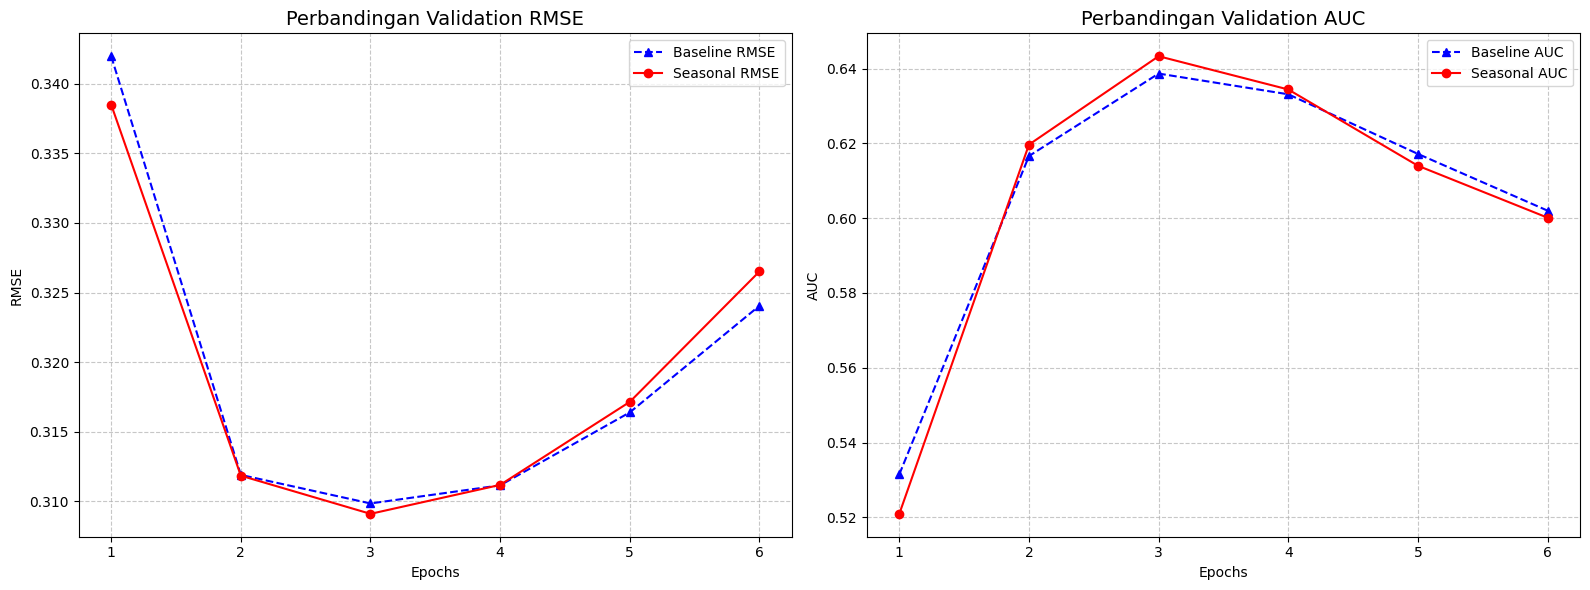


=== KESIMPULAN EVALUASI AKHIR ===
Baseline Model -> AUC: 0.6387 | RMSE: 0.3099
Seasonal Model -> AUC: 0.6433 | RMSE: 0.3091

Kesimpulan: Model Seasonal LEBIH BAIK karena memiliki AUC lebih tinggi dan RMSE lebih rendah. Hipotesis terbukti!


In [4]:
import matplotlib.pyplot as plt

# Ambil metrik validasi
epochs_baseline = range(1, len(history_baseline.history['val_rmse']) + 1)
epochs_seasonal = range(1, len(history_seasonal.history['val_rmse']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Validation RMSE
ax1.plot(epochs_baseline, history_baseline.history['val_rmse'], 'b--^', label='Baseline RMSE')
ax1.plot(epochs_seasonal, history_seasonal.history['val_rmse'], 'r-o', label='Seasonal RMSE')
ax1.set_title('Perbandingan Validation RMSE', fontsize=14)
ax1.set_xlabel('Epochs')
ax1.set_ylabel('RMSE')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

# Plot 2: Validation AUC
ax2.plot(epochs_baseline, history_baseline.history['val_auc'], 'b--^', label='Baseline AUC')
ax2.plot(epochs_seasonal, history_seasonal.history['val_auc'], 'r-o', label='Seasonal AUC')
ax2.set_title('Perbandingan Validation AUC', fontsize=14)
ax2.set_xlabel('Epochs')
ax2.set_ylabel('AUC')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Kesimpulan Evaluasi Akhir
base_eval = model_baseline.evaluate(X_test_baseline, y_test.values, verbose=0)
seas_eval = model_seasonal.evaluate(X_test_seasonal, y_test.values, verbose=0)

print("\n=== KESIMPULAN EVALUASI AKHIR ===")
print(f"Baseline Model -> AUC: {base_eval[1]:.4f} | RMSE: {base_eval[2]:.4f}")
print(f"Seasonal Model -> AUC: {seas_eval[1]:.4f} | RMSE: {seas_eval[2]:.4f}")

if seas_eval[1] > base_eval[1] and seas_eval[2] < base_eval[2]:
    print("\nKesimpulan: Model Seasonal LEBIH BAIK karena memiliki AUC lebih tinggi dan RMSE lebih rendah. Hipotesis terbukti!")
else:
    print("\nKesimpulan: Model Seasonal tidak selalu lebih superior. Silakan cek kurva atau lakukan fine-tuning lebih lanjut.")

### 5. Model Saving & Purwarupa Inference (Aplikasi Web)
Menyimpan model terbaik dan membuat fungsi *inference* untuk mensimulasikan *backend* aplikasi rekomendasi wisata.

In [6]:
import warnings
warnings.filterwarnings('ignore')

# Simpan model
MODEL_FILENAME = 'neumf_seasonal_model.h5'
model_seasonal.save(MODEL_FILENAME)
print(f"Model Seasonal berhasil disimpan sebagai '{MODEL_FILENAME}'\n")

def recommend_destinations(user_id, cuaca, top_k=5):
    """
    Fungsi untuk mensimulasikan inference backend aplikasi web.
    Menerima user_id dan kondisi cuaca, lalu mengembalikan top-K rekomendasi destinasi.
    """
    # 1. Validasi Input dan Transformasi
    try:
        # Gunakan handle_unknown='ignore' workaround jika encoder menemukan user/cuaca baru.
        # Untuk simulasi, kita asumsikan user_id dan cuaca ada di data latih.
        user_enc_val = encoders['user'].transform([user_id])[0]
        season_enc_val = encoders['season'].transform([cuaca])[0]
    except ValueError as e:
        return f"Error: Input tidak dikenali. {e}"

    # 2. Siapkan array untuk semua destinasi (items)
    all_items_encoded = np.arange(num_items)
    user_array = np.full(num_items, user_enc_val)
    season_array = np.full(num_items, season_enc_val)

    # 3. Prediksi skor
    # Load model (opsional di real app dipanggil sekali saat startup server)
    loaded_model = tf.keras.models.load_model(MODEL_FILENAME)

    # Predict probabilitas untuk setiap destinasi
    predictions = loaded_model.predict([user_array, all_items_encoded, season_array], verbose=0).flatten()

    # 4. Ambil Top-K
    top_indices = predictions.argsort()[-top_k:][::-1]
    top_item_encoded = all_items_encoded[top_indices]
    top_scores = predictions[top_indices]

    # 5. Decode hasil kembali ke nama aslinya
    top_destinations_asli = encoders['item'].inverse_transform(top_item_encoded)

    # Bentuk DataFrame untuk hasil
    result_df = pd.DataFrame({
        'Peringkat': range(1, top_k + 1),
        'ID Destinasi': top_destinations_asli,
        'Skor Rekomendasi': top_scores
    })

    return result_df

# --- Demonstrasi Simulasi Aplikasi Web ---
sample_user = df['user_id'].iloc[0]
sample_cuaca = df['rekomendasi_cuaca'].iloc[0] # Contoh: 'Cerah', 'Hujan', dll

print(f"\nMeminta Rekomendasi untuk:\n- User ID: {sample_user}\n- Cuaca Saat Ini: {sample_cuaca}\n")

top_recommendations = recommend_destinations(user_id=sample_user, cuaca=sample_cuaca, top_k=5)
display(top_recommendations)

Model Seasonal berhasil disimpan sebagai 'neumf_seasonal_model.h5'


Meminta Rekomendasi untuk:
- User ID: 861
- Cuaca Saat Ini: Kemarau & Penghujan



,Peringkat,ID Destinasi,Skor Rekomendasi
0,1,99,0.973382
1,2,46,0.962815
2,3,107,0.959705
3,4,22,0.956810
4,5,105,0.956081
